# v3 – Model evaluation and tuning (seminar unit 4)

The fourth model version. It applies the seminar notebook of unit 4 (*Modellbewertung und Hyperparameter-Tuning*) to our data and stays as close to it as possible. The data, target and preprocessing are those of [v2](v2_log_wind.ipynb), just as the seminar notebook takes the preprocessing of the previous unit.

![Flow of v3_cv_tuning](images/v3_cv_tuning_flow.png)

**How to read it:** grey is the data, blue the training on the development data (the training cases), orange the prediction and the scores on the test cases. The vertical arrow is what training hands over: the whole pipeline with the best settings, refitted on all development data. Steps with a thick border and a tag are new in this version.

| | v0–v2 | v3 (unit 4) |
|---|---|---|
| Data | training cases for fitting, test cases for scoring | training cases = **development data** for fitting, comparing and tuning; test cases used **once** at the end |
| Comparing models | on the test cases | 5-fold **cross-validation** on the development data |
| Model settings | fixed values from the template of unit 3 | decision-tree depth and leaf size chosen by **grid search** |
| Selection metric | – | mean absolute error of log(τ), fixed before tuning (2026-11-12) |
| Target, inputs | v2: log(τ), log(wind speed) | the same |
| New | | a classifier: does a setup reach 90 % within 600 s? (part 3 of unit 4) |

The workflow of unit 4:

1. separate development and test data,
2. set a baseline,
3. compare models with cross-validation,
4. choose hyperparameters on the development data,
5. score the chosen model once on the test data.

The column meanings are in [results/README.md](../results/README.md).

## 1) Setup

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

VERSION = "v3_cv_tuning"
RANDOM_STATE = 42
LN10 = np.log(10)  # t90 = ln(10) * tau, see v1

DATA_PATH = Path("../results/dataset_550/dataset_550.csv")
RESULTS_DIR = Path("results")
print("Data file:", DATA_PATH, "| found:", DATA_PATH.exists())

Data file: ../results/dataset_550/dataset_550.csv | found: True


## 2) Regression: predicting τ

### 2.1 Load the data and split it

The same data and the same split as in every version (v0, sections 2 and 3). The training cases are the **development data**: models are fitted, compared and tuned only on them. The test cases stay untouched until section 2.5.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df["status"] == "ok"].set_index("case_id")

TARGET_COL = "t90_s"
# Only values that are fixed before a simulation starts (same choice as in unit 2)
FEATURE_COLS = [
    "layout",
    "window1_x_m",
    "window1_mode",
    "window1_angle_deg",
    "window1_hinge",
    "window2_x_m",
    "window2_mode",
    "window2_angle_deg",
    "window2_hinge",
    "wind_speed_ms",
]

print("Simulations:", len(df))
print("Missing input values:", int(df[FEATURE_COLS].isna().sum().sum()))

t90_reached = df[TARGET_COL].notna()
display(pd.crosstab(
    df["layout"],
    t90_reached.map({True: "t90 reached", False: "t90 > 600 s"}),
    margins=True,
    margins_name="total",
))

Simulations: 541
Missing input values: 0


t90_s,t90 > 600 s,t90 reached,total
layout,,,
adjacent_walls,22,228,250
opposite_walls,20,230,250
same_wall,34,7,41
total,76,465,541


In [3]:
strata = df["layout"] + " / " + np.where(t90_reached, "reached", "not reached")

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=strata,
)

print("Training simulations:", len(train_df))
print("Test simulations:    ", len(test_df))
display(pd.crosstab(test_df["layout"], test_df[TARGET_COL].notna().map({True: "t90 reached", False: "t90 > 600 s"})))

Training simulations: 432
Test simulations:     109


t90_s,t90 > 600 s,t90 reached
layout,,
adjacent_walls,5,46
opposite_walls,4,46
same_wall,7,1


In [4]:
TAU_COL = "tau_s"

X_dev, y_dev = train_df[FEATURE_COLS], np.log(train_df[TAU_COL])
X_test, y_test = test_df[FEATURE_COLS], np.log(test_df[TAU_COL])

print("Development data:", X_dev.shape, y_dev.shape)
print("Test data:       ", X_test.shape, y_test.shape)

Development data: (432, 10) (432,)
Test data:        (109, 10) (109,)


As in v1 and v2, the target is log(τ). All scores in sections 2.2–2.5 are therefore scores of log(τ):

- an **MAE of log(τ)** of 0.22 means that τ is typically off by a factor of exp(0.22) ≈ 1.25, i.e. about 25 %;
- RMSE and R² are computed on log(τ) as well.

This MAE is the metric that selects the model. It was fixed before the tuning: a relative error counts the same for fast and for slow cases, and it uses every case.

### 2.2 Preprocessing and cross-validation

The preprocessing is that of v2: log(wind speed), standardised numeric inputs, one-hot encoded categorical inputs. Our inputs have no missing values, so there is no imputer.

For the cross-validation two things are fixed:

- `KFold` splits the development data into 5 parts, the *folds*. The model is trained 5 times; each fold is the validation data once, while the other 4 folds are used for training.
- `regression_scoring` lists the scores computed in every run. Its keys (`mae`, …) name the entries in the result of `cross_validate`.

| Parameter | Meaning |
|---|---|
| `n_splits=5` | number of folds, and so the number of training runs |
| `shuffle=True` | mixes the rows before the folds are made |
| `random_state=42` | makes the mixing, and so the folds, reproducible |

The whole pipeline is fitted anew in every fold, so the log, the scaling and the one-hot categories are learned from that fold's training part only.

In [5]:
num_cols = X_dev.select_dtypes(include="number").columns.tolist()
cat_cols = [col for col in FEATURE_COLS if col not in num_cols]
WIND_COL = "wind_speed_ms"
other_num_cols = [col for col in num_cols if col != WIND_COL]


def build_preprocessor():
    log_wind = Pipeline(steps=[
        ("log", FunctionTransformer(np.log, feature_names_out=lambda transformer, names: ["log_wind_speed"])),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        transformers=[
            ("wind", log_wind, [WIND_COL]),
            ("num", StandardScaler(), other_num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

regression_scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

print("Numeric inputs:    ", len(num_cols))
print("Categorical inputs:", len(cat_cols))

Numeric inputs:     5
Categorical inputs: 5


### 2.3 Baseline and two regression models

`DummyRegressor(strategy="median")` is the reference: it always predicts the median log(τ) of the training part of a fold, whatever the inputs. A trained model should beat it clearly.

`cross_validate` repeats training and scoring for every fold:

1. the pipeline is fitted anew in each fold,
2. the scores are computed on the held-out fold,
3. with `return_train_score=True`, also on the training part. A large gap between the two errors points to overfitting.

The result has one array per score with 5 values, one per fold. Mean and standard deviation summarise them. scikit-learn treats larger scores as better, so errors such as the MAE come back negative; the tables flip the sign.

Ridge and the decision tree use exactly the same folds and scores. As in unit 4, the tree starts without limits on its size.

In [6]:
baseline_pipeline = Pipeline(steps=[
    ("preprocess", build_preprocessor()),
    ("model", DummyRegressor(strategy="median")),
])

baseline_cv = cross_validate(
    baseline_pipeline,
    X_dev,
    y_dev,
    cv=regression_cv,
    scoring=regression_scoring,
    return_train_score=True,
)

In [7]:
ridge_pipeline = Pipeline(steps=[
    ("preprocess", build_preprocessor()),
    ("model", Ridge(alpha=10.0)),
])

ridge_cv = cross_validate(
    ridge_pipeline,
    X_dev,
    y_dev,
    cv=regression_cv,
    scoring=regression_scoring,
    return_train_score=True,
)

In [8]:
tree_pipeline = Pipeline(steps=[
    ("preprocess", build_preprocessor()),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE)),
])

tree_cv = cross_validate(
    tree_pipeline,
    X_dev,
    y_dev,
    cv=regression_cv,
    scoring=regression_scoring,
    return_train_score=True,
)

In [9]:
regression_comparison = pd.DataFrame({
    "model": ["Baseline (median)", "Ridge", "DecisionTree"],
    "training MAE": [-r["train_mae"].mean() for r in (baseline_cv, ridge_cv, tree_cv)],
    "CV MAE": [-r["test_mae"].mean() for r in (baseline_cv, ridge_cv, tree_cv)],
    "CV MAE std": [r["test_mae"].std() for r in (baseline_cv, ridge_cv, tree_cv)],
    "CV RMSE": [-r["test_rmse"].mean() for r in (baseline_cv, ridge_cv, tree_cv)],
    "CV R²": [r["test_r2"].mean() for r in (baseline_cv, ridge_cv, tree_cv)],
})
# The CV MAE of log(τ) as a typical relative error of τ
regression_comparison["typical τ error"] = (np.exp(regression_comparison["CV MAE"]) - 1).map("{:.0%}".format)

display(regression_comparison.round(3))

,model,training MAE,CV MAE,CV MAE std,CV RMSE,CV R²,typical τ error
0,Baseline (median),0.701,0.705,0.027,0.870,-0.014,102%
1,Ridge,0.218,0.227,0.015,0.273,0.900,25%
2,DecisionTree,-0.000,0.226,0.024,0.314,0.867,25%


Three questions for the comparison:

- Does a model predict clearly better than the baseline?
- How much do the results vary between the folds (*CV MAE std*)?
- How far apart are the training and the validation error?

### 2.4 Hyperparameters of the decision tree

`GridSearchCV` combines a systematic search with cross-validation: every combination of `max_depth` and `min_samples_leaf` gets a full 5-fold cross-validation. The grid is the one of unit 4.

The parameter names have the prefix `model__` because the tree is the pipeline step `model`; pipeline parameters are addressed as `<step>__<parameter>`.

| Element | Meaning |
|---|---|
| `estimator` | the pipeline that is examined |
| `param_grid` | the values to try; all combinations are scored |
| `scoring` | the score that selects the best combination, here the MAE of log(τ) |
| `cv` | how the development data are split |
| `n_jobs=-1` | use all processor cores |
| `best_params_` | the combination with the best mean CV score |
| `best_score_` | its mean CV score |
| `cv_results_` | the results of all combinations |
| `best_estimator_` | the pipeline with the best parameters, fitted again on all development data |

Because of the final refit, `best_estimator_` can be used directly for the test in section 2.5.

In [10]:
param_grid = {
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 3, 5, 10],
}

tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=regression_cv,
    n_jobs=-1,
    return_train_score=True,
)

tree_search.fit(X_dev, y_dev)

print("Best parameters:", tree_search.best_params_)
print(f"Best CV MAE of log(τ): {-tree_search.best_score_:.3f} (τ typically off by {np.exp(-tree_search.best_score_) - 1:.0%})")

Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 1}
Best CV MAE of log(τ): 0.219 (τ typically off by 24%)


In [11]:
tuning_results = pd.DataFrame(tree_search.cv_results_)
tuning_results["mean_train_mae"] = -tuning_results["mean_train_score"]
tuning_results["mean_cv_mae"] = -tuning_results["mean_test_score"]

display(
    tuning_results[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "mean_train_mae",
            "mean_cv_mae",
            "std_test_score",
        ]
    ]
    .sort_values("mean_cv_mae")
    .head(10)
    .round(3)
)

,param_model__max_depth,param_model__min_samples_leaf,mean_train_mae,mean_cv_mae,std_test_score
8,8,1,0.065,0.219,0.022
12,None,1,-0.000,0.226,0.024
9,8,3,0.106,0.232,0.021
13,None,3,0.092,0.234,0.023
4,5,1,0.176,0.247,0.028
5,5,3,0.187,0.259,0.015
14,None,5,0.154,0.278,0.015
10,8,5,0.158,0.279,0.019
6,5,5,0.211,0.292,0.019
11,8,10,0.229,0.324,0.022


### 2.5 Final evaluation on the test cases

`best_estimator_` is the complete pipeline with the selected parameters, already fitted on all development data. Now the test cases are used for the first and only time.

`predict(X_test)` first applies the learned preprocessing and then the tree. The scores of unit 4 (MAE, RMSE, R²) are computed on log(τ). For the comparison with v0–v2, the same pipeline's τ is also turned into t90 and scored on the 93 test cases with a t90 value.

The plots check the result visually:

- left: good predictions lie close to the diagonal;
- right: the *residual* is `simulated − predicted`. A pattern in the residuals points to a relationship the model has not captured.

In [12]:
best_regressor = tree_search.best_estimator_
y_pred = best_regressor.predict(X_test)

test_results = pd.Series({
    "MAE of log(τ)": mean_absolute_error(y_test, y_pred),
    "RMSE of log(τ)": root_mean_squared_error(y_test, y_pred),
    "R² of log(τ)": r2_score(y_test, y_pred),
})

display(test_results.round(3).to_frame("test value"))

,test value
MAE of log(τ),0.238
RMSE of log(τ),0.323
R² of log(τ),0.867


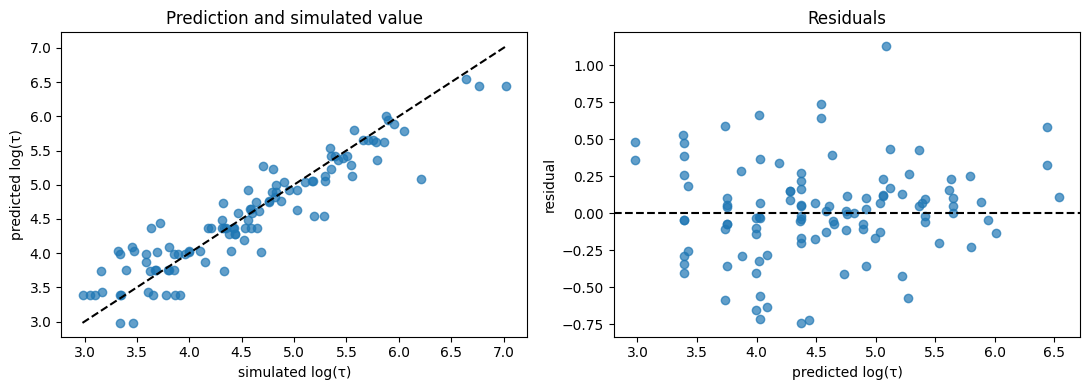

In [13]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(y_test, y_pred, alpha=0.7)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set_xlabel("simulated log(τ)")
axes[0].set_ylabel("predicted log(τ)")
axes[0].set_title("Prediction and simulated value")

axes[1].scatter(y_pred, residuals, alpha=0.7)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set_xlabel("predicted log(τ)")
axes[1].set_ylabel("residual")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

**For the comparison with v0–v2:** t90 = ln(10) · τ on the same 93 test cases with a t90 value. This is only reported; nothing is selected with it.

In [14]:
has_t90 = test_df[TARGET_COL].notna()
y_test_t90 = test_df.loc[has_t90, TARGET_COL]
t90_pred = pd.Series(LN10 * np.exp(y_pred), index=X_test.index)

t90_results = pd.Series({
    "MAE [s]": mean_absolute_error(y_test_t90, t90_pred[has_t90]),
    "RMSE [s]": root_mean_squared_error(y_test_t90, t90_pred[has_t90]),
    "R²": r2_score(y_test_t90, t90_pred[has_t90]),
})
display(t90_results.round(3).to_frame("tuned DecisionTree, t90 on the 93"))

earlier = pd.concat([
    pd.read_csv(RESULTS_DIR / f"{v}.csv") for v in ["v0_base", "v1_tau", "v2_log_wind"]
])
display(earlier[earlier["model"] != "Mean value (reference)"][["version", "model", "MAE [s]", "R²"]].round(3))

,"tuned DecisionTree, t90 on the 93"
MAE [s],43.805
RMSE [s],64.199
R²,0.795


,version,model,MAE [s],R²
1,v0_base,LinearRegression,53.050,0.753
2,v0_base,Ridge,53.450,0.734
3,v0_base,DecisionTree,42.081,0.806
1,v1_tau,LinearRegression,50.206,0.713
2,v1_tau,Ridge,50.135,0.704
3,v1_tau,DecisionTree,57.922,0.638
1,v2_log_wind,LinearRegression,47.322,0.745
2,v2_log_wind,Ridge,47.252,0.736
3,v2_log_wind,DecisionTree,57.922,0.638


## 3) Transfer to a classification task

Part 3 of unit 4 shows the same workflow for classification. In our data a natural yes/no question is: **does a setup reach 90 % fresh air within 600 s?** The cases without a t90 value do not.

- Class 1 (*positive*): **t90 > 600 s**, the room is not aired out within 10 minutes. 60 of the 432 development cases.
- Class 0: t90 ≤ 600 s.

The positive class is the rarer one, and the one that matters: a model that misses it would tell a user that 10 minutes are enough when they are not.

The shared split is already stratified by this class, so the development and test data are the same as in part 2. `StratifiedKFold` keeps the class shares in the folds too. Unlike the example in unit 4, our inputs contain categories, so the classifier gets the same preprocessing as the regression.

In [15]:
y_dev_cls = train_df[TARGET_COL].isna().astype(int)  # 1 = t90 > 600 s
y_test_cls = test_df[TARGET_COL].isna().astype(int)
class_names = ["t90 ≤ 600 s", "t90 > 600 s"]

print("Development data:", y_dev_cls.value_counts().sort_index().to_dict())
print("Test data:       ", y_test_cls.value_counts().sort_index().to_dict())

classification_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

classification_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

Development data: {0: 372, 1: 60}
Test data:        {0: 93, 1: 16}


### 3.1 Baseline and classification model

`DummyClassifier(strategy="most_frequent")` always predicts the most frequent class of the training part, here "t90 ≤ 600 s". It is right in about 86 % of the cases, yet it never finds a single slow case: its precision, recall and F1 are 0. (scikit-learn warns that the precision is undefined when nothing is predicted positive; the warning is switched off and the value counted as 0.)

The logistic regression gets the preprocessing and is scored with the same folds:

- **Accuracy**: share of all correct predictions,
- **Precision**: of the cases predicted as "t90 > 600 s", the share that really are,
- **Recall**: of the cases that really are "t90 > 600 s", the share that is found,
- **F1**: harmonic mean of precision and recall,
- **ROC-AUC**: how well the classes are separated over all decision thresholds.

For us the recall matters most: a missed slow case is the worse error.

In [16]:
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

baseline_classifier = DummyClassifier(strategy="most_frequent")

baseline_cls_cv = cross_validate(
    baseline_classifier,
    X_dev,
    y_dev_cls,
    cv=classification_cv,
    scoring=classification_scoring,
)

logistic_pipeline = Pipeline(steps=[
    ("preprocess", build_preprocessor()),
    ("model", LogisticRegression(max_iter=2000)),
])

logistic_cv = cross_validate(
    logistic_pipeline,
    X_dev,
    y_dev_cls,
    cv=classification_cv,
    scoring=classification_scoring,
)

In [17]:
classification_comparison = pd.DataFrame({
    "model": ["Baseline (most frequent)", "LogisticRegression"],
    **{
        score: [baseline_cls_cv[f"test_{score}"].mean(), logistic_cv[f"test_{score}"].mean()]
        for score in classification_scoring
    },
})

display(classification_comparison.round(3))

,model,accuracy,precision,recall,f1,roc_auc
0,Baseline (most frequent),0.861,0.000,0.00,0.000,0.500
1,LogisticRegression,0.961,0.963,0.75,0.838,0.991


### 3.2 Choose the hyperparameter and score on the test data

As in part 2, with the grid and the selection score of unit 4: `C` sets the regularisation of the logistic regression (small values: strong regularisation), and the F1 score selects it.

`best_estimator_` is again the selected, refitted pipeline. On the test data:

- `classification_report` gives precision, recall and F1 for both classes and several averages;
- the confusion matrix counts the right and wrong predictions by true and predicted class.

In [18]:
classification_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0]},
    scoring="f1",
    cv=classification_cv,
    n_jobs=-1,
)

classification_search.fit(X_dev, y_dev_cls)

best_classifier = classification_search.best_estimator_
y_pred_cls = best_classifier.predict(X_test)

print("Best parameters:", classification_search.best_params_)
print(f"Best CV F1: {classification_search.best_score_:.3f}")
print()
print(classification_report(
    y_test_cls,
    y_pred_cls,
    target_names=class_names,
))

Best parameters: {'model__C': 10.0}
Best CV F1: 0.864

              precision    recall  f1-score   support

 t90 ≤ 600 s       0.97      0.98      0.97        93
 t90 > 600 s       0.87      0.81      0.84        16

    accuracy                           0.95       109
   macro avg       0.92      0.90      0.91       109
weighted avg       0.95      0.95      0.95       109



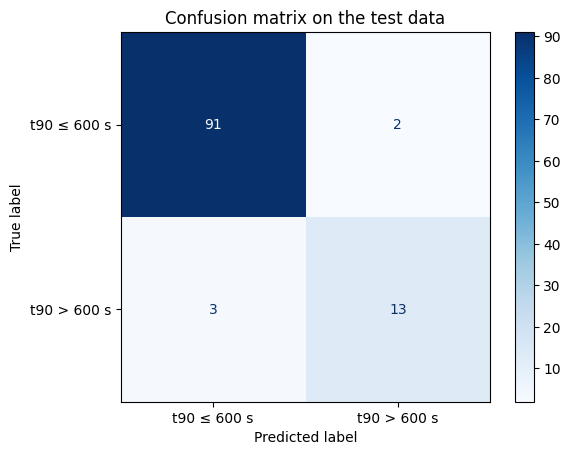

In [19]:
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    y_pred_cls,
    display_labels=class_names,
    cmap="Blues",
)
plt.title("Confusion matrix on the test data")
plt.show()

## 4) Save the results

As in the earlier versions: `results/v3_cv_tuning.csv` holds the t90 scores of the selected regression pipeline on the 93 test cases, `results/v3_cv_tuning_test_predictions.csv` its predicted t90 and τ for all 109 test cases, plus the classifier's prediction.

In [20]:
params = tree_search.best_params_
model_name = f"DecisionTree (depth {params['model__max_depth']}, leaf {params['model__min_samples_leaf']})"
summary = pd.DataFrame([{
    "version": VERSION,
    "model": model_name,
    **t90_results.to_dict(),
    "target": "log(tau_s)",
    "n_train": len(X_dev),
    "n_test": len(y_test_t90),
}])
summary.to_csv(RESULTS_DIR / f"{VERSION}.csv", index=False, float_format="%.3f")

test_predictions = pd.DataFrame({
    "t90_s simulated": test_df[TARGET_COL],
    "tau_s simulated": test_df[TAU_COL],
    f"t90 {model_name}": t90_pred,
    f"tau {model_name}": np.exp(y_pred),
    "classifier: t90 > 600 s": y_pred_cls,
}, index=X_test.index)
test_predictions.to_csv(RESULTS_DIR / f"{VERSION}_test_predictions.csv", index_label="case_id", float_format="%.1f")
display(summary.round(3))

,version,model,MAE [s],RMSE [s],R²,target,n_train,n_test
0,v3_cv_tuning,"DecisionTree (depth 8, leaf 1)",43.805,64.199,0.795,log(tau_s),432,93


## 5) Summary and findings

The workflow of unit 4 runs on our data without changes: the development data for all choices, cross-validation for comparing, a grid search for the tree, the test cases once at the end.

**Regression, cross-validation** (432 development cases, MAE of log(τ)):

- The baseline is off by about a factor of 2 (CV MAE 0.71). Ridge (0.227 ± 0.015) and the unlimited tree (0.226 ± 0.024) are both typically about 25 % off.
- The unlimited tree fits its training data perfectly (training MAE 0): clear overfitting, yet its validation error equals Ridge's.
- The grid search picks depth 8 with leaf size 1 (CV MAE 0.219 ± 0.022). The best candidates differ by less than the variation between the folds.
- Ridge has the lower CV RMSE (0.27 vs 0.31) and the higher R² (0.90 vs 0.87): the tree makes smaller typical errors but more large ones. Which model "wins" depends on the selection metric, as unit 4 points out; ours, the MAE of log(τ), was fixed before the tuning.

**Regression, test** (once, tuned tree): MAE of log(τ) 0.238, a little worse than in the cross-validation (0.219), as is normal for a selected model. R² of log(τ) 0.87. Converted to t90 on the 93 test cases: **MAE 44 s, R² 0.80**, close to v0's tree (42 s, 0.81) and better in t90 than v2's linear model (47 s, 0.75). On log(τ) over all 109 test cases, v2's linear model is better (MAE 0.216 vs 0.238, from its saved predictions; only reported, not used to select). The tree predicts in steps, visible as vertical stripes in the residual plot.

**Classification** (t90 > 600 s, yes or no):

- The baseline is right in 86 % of the cases but finds no slow case. The logistic regression reaches a CV F1 of 0.84 and a ROC-AUC of 0.99.
- The grid search picks C = 10, the largest value of the grid, so the best value may lie beyond it.
- Test: **13 of the 16 slow cases are found** (recall 0.81) with 2 false alarms among the 93 others (precision 0.87); 3 slow cases are missed. For comparison, v2's regression found 11 of 16.

**Limits of v3:** like unit 4, it tunes only the tree and then tests the tuned tree. Ridge and LinearRegression were not tuned and not compared with the tuned tree before the test.

**Options for the next version (v4):**

1. Compare the tuned tree with a tuned Ridge (and LinearRegression) in one cross-validation table, and select the model type that way before the test.
2. Extend the grid of `C` beyond 10 for the classifier.
3. Random forest or gradient boosting: they average many trees, which gives fewer steps and less overfitting.
4. Save the finally chosen pipeline with `joblib`, as in the second notebook of unit 4.